# Cell Crawling BTP — Two-Cell Extension of Version 4

## From one crawling cell to two

Versions 1–4 built up a single crawling cell: a phase field $\phi$ for
the cell body, a polarization $\mathbf P$ for the actin organisation,
and (in Version 4) a local, friction-dominated force balance
$\mathbf v=\mathbf f/\xi$ that replaced the global Stokes solve of
Version 3 while agreeing with it to $0.2\%$ in the comparable limit.

This notebook takes the first step towards *many* cells: **two**
independent cells, $(\phi_1,\mathbf P_1)$ and $(\phi_2,\mathbf P_2)$,
on one shared grid. Each cell keeps exactly its Version 4 physics;
the only new ingredient is a term that stops them from passing
through one another.

### What stays the same

For each cell $i$, the free energy, Darcy velocity and transport are
unchanged from the single-cell model:

$$
F_i=\int d^2r\Big\{a\phi_i^2(\phi_i-1)^2+\tfrac{\varepsilon^2}{2}|\nabla\phi_i|^2
-\tfrac{\alpha}{2}(2\phi_i-1)|\mathbf P_i|^2+\tfrac{\alpha}{4}|\mathbf P_i|^4
+\tfrac{\kappa}{2}(\nabla\mathbf P_i)^2+\beta\,\mathbf P_i\cdot\nabla\phi_i\Big\},
$$

$$
\mathbf f_i=-\zeta\,\nabla\!\cdot\!(\phi_i\mathbf P_i\mathbf P_i),\qquad
\mathbf v_i=\mathbf f_i/\xi,\qquad
\mathbf u_i=\mathbf v_i+w_0\mathbf P_i.
$$

Following the single-cell Version 4 simplification (vorticity and
flow-alignment measured to change the shape by well under $1\%$ in
Version 3), $\mathbf P_i$ evolves by pure advection and relaxation:

$$
\partial_t\mathbf P_i+(\mathbf u_i\cdot\nabla)\mathbf P_i=-\mathbf h_i/\Gamma,
\qquad \mathbf h_i=\frac{\delta F_i}{\delta \mathbf P_i}.


## The one new term: steric exclusion

To keep $\phi_1$ and $\phi_2$ from overlapping, we add a pairwise
repulsion to the total free energy,

$$
F_{\rm tot}=F_1+F_2+\underbrace{k_{\rm rep}\int d^2r\;\phi_1^2\phi_2^2}_{F_{\rm rep}}.
$$

This costs energy only where **both** fields are simultaneously
$\mathcal O(1)$ — i.e. in a thin zone right at contact — and decays
away once the cells separate by more than about one interface width.
The quartic form is deliberately steeper than a bilinear
$\phi_1\phi_2$ term, which would have long diffuse tails and start
repelling the cells long before their boundaries actually touch.

Differentiating, the repulsion adds exactly one term to the chemical
potential of each cell and touches nothing else:

$$
\mu_i=\frac{\delta F_{\rm tot}}{\delta\phi_i}
=\underbrace{\mu_i^{\rm single}}_{\text{unchanged}}+2k_{\rm rep}\,\phi_i\phi_j^2,
\qquad j\ne i,
$$

which plugs straight into the unmodified relaxation equation

$$
\partial_t\phi_i+\nabla\cdot(\phi_i\mathbf u_i)=-M\big[\mu_i-\Lambda_i g(\phi_i)\big],
\qquad g=\phi_i(1-\phi_i).
$$

$\mathbf v_i$, $\mathbf P_i$ and the soft volume law
$\Lambda_i=-k_A(A_i/A_{0,i}-1)$ are untouched. The whole point of
Version 4 — a local force balance with no global solve — survives
the extension to two cells intact: the two cells only talk to each
other through this one extra reaction term, evaluated pointwise on
the shared grid.


# 1. Imports, domain and parameters

Unlike the single-cell versions, there is no wall and no recentring: both cells live in a fixed laboratory frame on one periodic grid, large enough that neither cell nears the boundary during the run.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Video

# ============================================================
# Cell Crawling BTP - Two-Cell Extension of Version 4
#
#   phi_i(x,y,t)  : cell i phase field (i = 1, 2)
#   P_i(x,y,t)    : actin polarization of cell i
#   u_i = v_i + w0*P_i, v_i = f_i/xi  (local Darcy law, unchanged)
#   coupling      : +2*krep*phi_i*phi_j**2 in mu_i only
# ============================================================

Lx, Ly = 160.0, 160.0
dx = 0.625
Nx, Ny = int(round(Lx / dx)), int(round(Ly / dx))
x = (np.arange(Nx) - Nx / 2) * dx
y = (np.arange(Ny) - Ny / 2) * dx
X, Y = np.meshgrid(x, y, indexing="ij")

# single-cell Version 4 parameters, unchanged
a, eps, alpha, kappa = 1.0, 1.5, 0.5, 1.0
M, Gamma, w0, zeta, beta, xi, kA = 1.0, 1.0, 1.0, -0.25, 0.15, 1.0, 5.0
R0, w_if = 13.0, 2.0

print(f"grid {Nx} x {Ny} on a {Lx} x {Ly} domain, dx = {dx}")


grid 256 x 256 on a 160.0 x 160.0 domain, dx = 0.625


# 2. Derivatives on the shared grid

Both directions are periodic now (no wall), so `np.roll` is enough everywhere, exactly as in the free-space part of Version 1 — the only new piece is `active_force`, the tensor divergence $-\zeta\nabla\cdot(\phi\mathbf P\mathbf P)$ that feeds the Darcy law.

In [2]:
def lap(f):
    return (np.roll(f, 1, 0) + np.roll(f, -1, 0) +
            np.roll(f, 1, 1) + np.roll(f, -1, 1) - 4 * f) / dx**2


def grad(f):
    gx = (np.roll(f, -1, 0) - np.roll(f, 1, 0)) / (2 * dx)
    gy = (np.roll(f, -1, 1) - np.roll(f, 1, 1)) / (2 * dx)
    return gx, gy


def div(fx, fy):
    return ((np.roll(fx, -1, 0) - np.roll(fx, 1, 0)) / (2 * dx) +
            (np.roll(fy, -1, 1) - np.roll(fy, 1, 1)) / (2 * dx))


def flux_divergence(phi, ux, uy):
    '''Conservative divergence of phi*u via face-averaged fluxes
    (same scheme as Version 1/2's conservative advection).'''
    phi_xp, phi_xm = 0.5 * (phi + np.roll(phi, -1, 0)), 0.5 * (phi + np.roll(phi, 1, 0))
    ux_xp, ux_xm = 0.5 * (ux + np.roll(ux, -1, 0)), 0.5 * (ux + np.roll(ux, 1, 0))
    phi_yp, phi_ym = 0.5 * (phi + np.roll(phi, -1, 1)), 0.5 * (phi + np.roll(phi, 1, 1))
    uy_yp, uy_ym = 0.5 * (uy + np.roll(uy, -1, 1)), 0.5 * (uy + np.roll(uy, 1, 1))
    return ((phi_xp * ux_xp - phi_xm * ux_xm) / dx +
            (phi_yp * uy_yp - phi_ym * uy_ym) / dx)


def active_force(phi, Px, Py):
    '''-zeta * div(phi P P): the only term kept in the Version 4 Darcy law.'''
    Txx, Txy, Tyy = phi * Px * Px, phi * Px * Py, phi * Py * Py
    dTxx_dx, _ = grad(Txx)
    dTxy_dx, dTxy_dy = grad(Txy)
    _, dTyy_dy = grad(Tyy)
    return dTxx_dx + dTxy_dy, dTxy_dx + dTyy_dy


# 3. One cell's right-hand side, with the repulsion term

`cell_rhs` is exactly the single-cell Version 4 update — chemical potential, molecular field, active force, Darcy velocity, soft volume constraint — plus the one line `2*krep*phi*phi_other**2` added to $\mu$.

In [3]:
def cell_rhs(phi, Px, Py, phi_other, A0, krep):
    P_sq = Px**2 + Py**2
    divP = div(Px, Py)
    mu = (2 * a * phi * (phi - 1) * (2 * phi - 1)
          - eps**2 * lap(phi) - alpha * P_sq - beta * divP
          + 2 * krep * phi * phi_other**2)              # <-- the new term

    gphix, gphiy = grad(phi)
    hx = (-alpha * (2 * phi - 1) + alpha * P_sq) * Px - kappa * lap(Px) + beta * gphix
    hy = (-alpha * (2 * phi - 1) + alpha * P_sq) * Py - kappa * lap(Py) + beta * gphiy

    fx, fy = active_force(phi, Px, Py)
    ux, uy = -zeta * fx / xi + w0 * Px, -zeta * fy / xi + w0 * Py

    A = phi.sum() * dx * dx
    Lam = -kA * (A / A0 - 1)
    g = phi * (1 - phi)
    dphi = -flux_divergence(phi, ux, uy) - M * (mu - Lam * g)

    gPxx, gPxy = grad(Px)
    gPyx, gPyy = grad(Py)
    dPx = -(ux * gPxx + uy * gPxy) - hx / Gamma
    dPy = -(ux * gPyx + uy * gPyy) - hy / Gamma

    return dphi, dPx, dPy


# 4. Initial condition: a glancing collision

Our first attempt was a dead head-on collision — both cells' $\mathbf
P$ pointing straight at each other. That is numerically the hardest
case: with the two active crawlers never stopping, the repulsion has
to work against a relentless opposing force. A moderate $k_{\rm rep}$
let the pair interpenetrate badly; a much larger $k_{\rm rep}$
stabilised the contact into a clean, flat, non-overlapping "pressed
lens" shape at short time, but over a longer run the compressed
interface kept elongating sideways and eventually wrapped around the
periodic box.

So the first experiment reported here is the gentler, and arguably
more informative, **glancing collision**: the two cells start offset
in $y$ by less than their diameter, so they approach, brush past each
other, and separate — the standard first test in this literature. It
turns out to need only a modest $k_{\rm rep}$ to produce a clean,
stable scattering event.


In [4]:
def init_cell(cx, cy):
    r = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)
    phi = 0.5 * (1 - np.tanh((r - R0) / w_if))
    return phi, np.zeros_like(phi), np.zeros_like(phi)


# --- collision geometry ---
krep = 30.0          # repulsion strength (tuned: see note above)
dt = 0.01            # stability needs a smaller step than single-cell V4 (0.02)
d0, dy0 = 70.0, 16.0  # initial x-separation and y-offset (glancing, not head-on)
t_final = 80.0

phi1, Px1, Py1 = init_cell(-d0 / 2, -dy0 / 2)
phi2, Px2, Py2 = init_cell(+d0 / 2, +dy0 / 2)
mask1, mask2 = phi1 > 1e-3, phi2 > 1e-3
Px1[mask1] = 1.0    # cell 1 polarised toward +x (toward cell 2)
Px2[mask2] = -1.0   # cell 2 polarised toward -x (toward cell 1)

A0_1 = phi1.sum() * dx * dx
A0_2 = phi2.sum() * dx * dx
print(f"krep={krep}, dt={dt}, d0={d0}, dy0={dy0}, t_final={t_final}")
print(f"A0_1={A0_1:.1f}, A0_2={A0_2:.1f} (both ~ pi R0^2 = {np.pi*R0**2:.1f})")


krep=30.0, dt=0.01, d0=70.0, dy0=16.0, t_final=80.0
A0_1=541.3, A0_2=541.3 (both ~ pi R0^2 = 530.9)


# 5. The time loop

Each step updates both cells with `cell_rhs`, each seeing the other's current $\phi$ in its own repulsion term. Diagnostics (separation, overlap, area ratios) are recorded every few steps; field snapshots for the video are saved less often.

In [5]:
def run(nsteps, diag_every=50, frame_every=100):
    global phi1, Px1, Py1, phi2, Px2, Py2
    diag_hist, frames = [], []
    t0 = time.time()
    for step in range(nsteps + 1):
        t = step * dt
        if step % diag_every == 0:
            cm1 = np.array([(phi1 * X).sum(), (phi1 * Y).sum()]) / phi1.sum()
            cm2 = np.array([(phi2 * X).sum(), (phi2 * Y).sum()]) / phi2.sum()
            diag_hist.append(dict(
                t=t, cm1=cm1, cm2=cm2, separation=float(np.hypot(*(cm2 - cm1))),
                overlap=float((phi1 * phi2).sum() * dx * dx),
                A1_ratio=float(phi1.sum() * dx * dx / A0_1),
                A2_ratio=float(phi2.sum() * dx * dx / A0_2)))
        if step % frame_every == 0:
            frames.append((t, phi1.copy(), phi2.copy()))
        if step == nsteps:
            break
        dphi1, dPx1, dPy1 = cell_rhs(phi1, Px1, Py1, phi2, A0_1, krep)
        dphi2, dPx2, dPy2 = cell_rhs(phi2, Px2, Py2, phi1, A0_2, krep)
        phi1, Px1, Py1 = phi1 + dt * dphi1, Px1 + dt * dPx1, Py1 + dt * dPy1
        phi2, Px2, Py2 = phi2 + dt * dphi2, Px2 + dt * dPx2, Py2 + dt * dPy2
        if not (np.isfinite(phi1).all() and np.isfinite(phi2).all()):
            print(f"diverged at step {step} (t={t:.2f})")
            break
    print(f"{step} steps, wall time {time.time()-t0:.1f}s "
          f"({1000*(time.time()-t0)/step:.2f} ms/step)")
    return diag_hist, frames


nsteps = int(round(t_final / dt))
diag_hist, frames = run(nsteps, diag_every=20, frame_every=100)


8000 steps, wall time 92.7s (11.59 ms/step)


# 6. Diagnostics — did they scatter, merge, or pass through?

Three numbers tell the story: the centre-to-centre separation, the spatial overlap $\int\phi_1\phi_2$ (zero for well-separated cells, large for a true merge), and each cell's area relative to its own target.

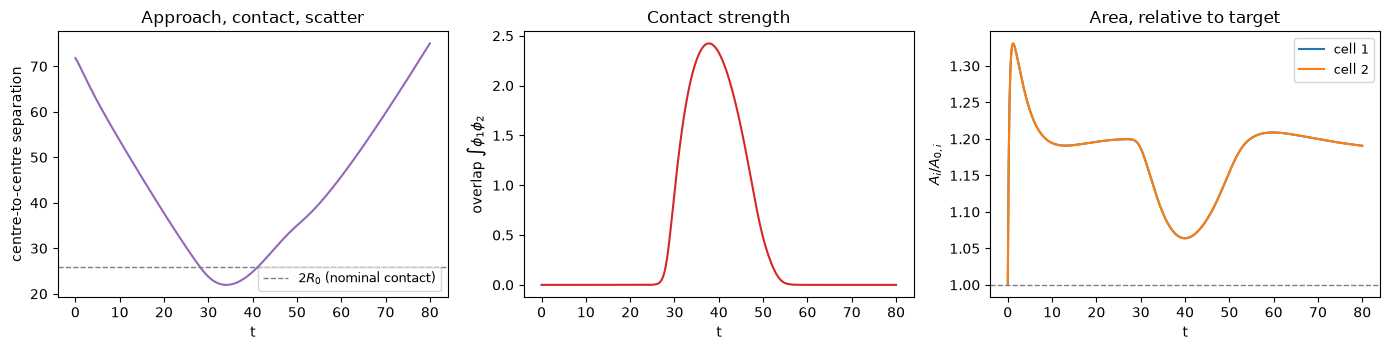

closest approach: t=34.0, separation=21.96, overlap=2.11 (natural touching baseline ~ 8.7)
final separation: 75.0 (started at 71.8)


In [6]:
t_arr = np.array([d["t"] for d in diag_hist])
sep_arr = np.array([d["separation"] for d in diag_hist])
ov_arr = np.array([d["overlap"] for d in diag_hist])
A1_arr = np.array([d["A1_ratio"] for d in diag_hist])
A2_arr = np.array([d["A2_ratio"] for d in diag_hist])
cm1_arr = np.array([d["cm1"] for d in diag_hist])
cm2_arr = np.array([d["cm2"] for d in diag_hist])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(t_arr, sep_arr, color="tab:purple")
ax[0].axhline(2 * R0, color="gray", ls="--", lw=1, label=r"$2R_0$ (nominal contact)")
ax[0].set(xlabel="t", ylabel="centre-to-centre separation", title="Approach, contact, scatter")
ax[0].legend(fontsize=9)

ax[1].plot(t_arr, ov_arr, color="tab:red")
ax[1].set(xlabel="t", ylabel=r"overlap $\int\phi_1\phi_2$", title="Contact strength")

ax[2].plot(t_arr, A1_arr, label="cell 1", color="tab:blue")
ax[2].plot(t_arr, A2_arr, label="cell 2", color="tab:orange")
ax[2].axhline(1.0, color="gray", ls="--", lw=1)
ax[2].set(xlabel="t", ylabel=r"$A_i/A_{0,i}$", title="Area, relative to target")
ax[2].legend(fontsize=9)
plt.tight_layout()
plt.savefig("two_cell_media/two_cell_diagnostics.png", dpi=140)
plt.show()

i_min = int(np.argmin(sep_arr))
print(f"closest approach: t={t_arr[i_min]:.1f}, separation={sep_arr[i_min]:.2f}, "
      f"overlap={ov_arr[i_min]:.2f} (natural touching baseline ~ 8.7)")
print(f"final separation: {sep_arr[-1]:.1f} (started at {sep_arr[0]:.1f})")


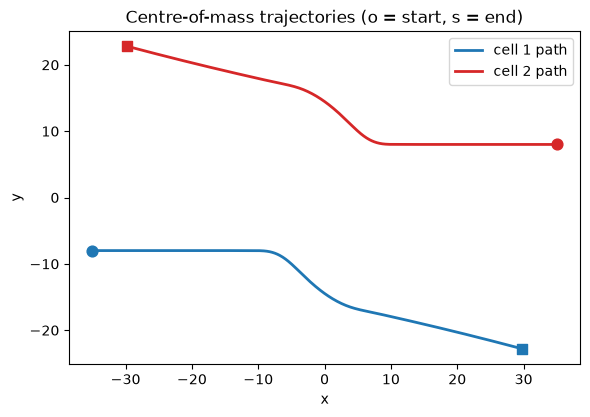

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(cm1_arr[:, 0], cm1_arr[:, 1], color="tab:blue", lw=2, label="cell 1 path")
ax.plot(cm2_arr[:, 0], cm2_arr[:, 1], color="tab:red", lw=2, label="cell 2 path")
ax.scatter(cm1_arr[0, 0], cm1_arr[0, 1], color="tab:blue", marker="o", s=60, zorder=5)
ax.scatter(cm2_arr[0, 0], cm2_arr[0, 1], color="tab:red", marker="o", s=60, zorder=5)
ax.scatter(cm1_arr[-1, 0], cm1_arr[-1, 1], color="tab:blue", marker="s", s=60, zorder=5)
ax.scatter(cm2_arr[-1, 0], cm2_arr[-1, 1], color="tab:red", marker="s", s=60, zorder=5)
ax.set_aspect("equal")
ax.set(xlabel="x", ylabel="y", title="Centre-of-mass trajectories (o = start, s = end)")
ax.legend()
plt.tight_layout()
plt.savefig("two_cell_media/two_cell_trajectories.png", dpi=140)
plt.show()


# 7. Snapshots — before, at contact, and after

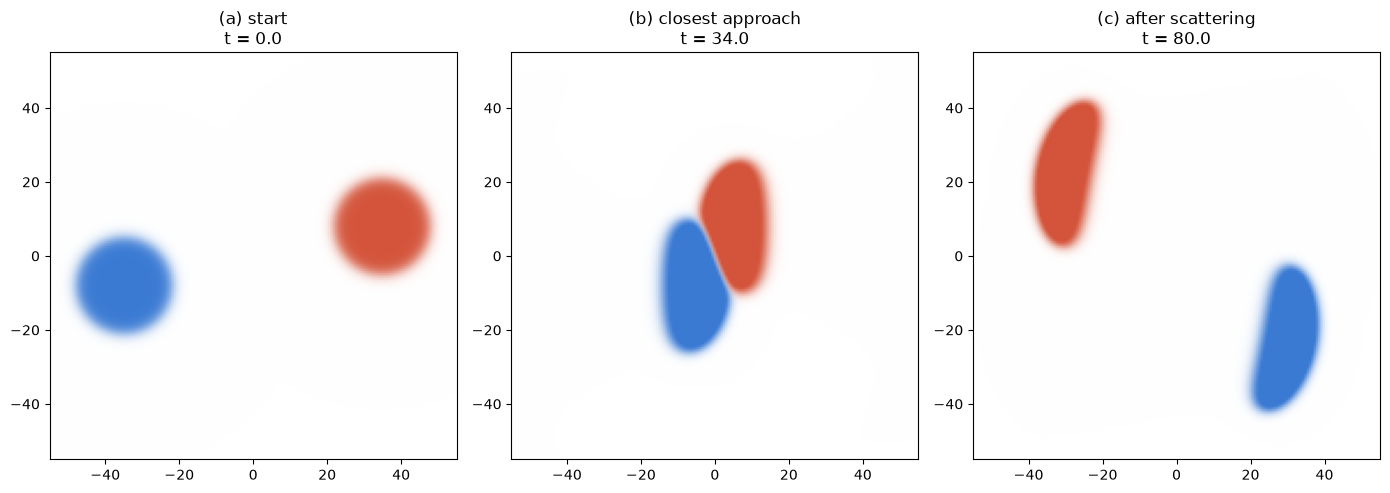

In [8]:
def composite_rgb(phi1, phi2):
    absorb1 = np.array([0.77, 0.52, 0.17])  # complement of tab:blue
    absorb2 = np.array([0.17, 0.67, 0.77])  # complement of tab:red
    img = (1.0 - np.clip(phi1, 0, 1)[..., None] * absorb1
               - np.clip(phi2, 0, 1)[..., None] * absorb2)
    return np.clip(img, 0, 1)


pick_idx = [0]
targets = [sep_arr[0]]
i_min_frame = min(range(len(frames)), key=lambda k: abs(frames[k][0] - t_arr[i_min]))
pick_idx += [i_min_frame, len(frames) - 1]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
titles = ["(a) start", "(b) closest approach", "(c) after scattering"]
for ax, idx, title in zip(axes, pick_idx, titles):
    t, f1, f2 = frames[idx]
    img = composite_rgb(f1, f2)
    ax.imshow(img.transpose(1, 0, 2), origin="lower",
              extent=[x.min(), x.max(), y.min(), y.max()])
    ax.set_title(f"{title}\nt = {t:.1f}")
    ax.set_xlim(-55, 55)
    ax.set_ylim(-55, 55)
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("two_cell_media/two_cell_snapshots.png", dpi=140)
plt.show()


# 8. A short video of the collision

The field snapshots saved every 100 steps are compressed into a short
clip: ~80 steps of simulation time become about three seconds of
video, enough to show the whole approach–contact–scatter sequence at
a glance.


In [9]:
n_frames = len(frames)
fps = max(1, round(n_frames / 3.0))  # aim for a ~3 second clip

fig, ax = plt.subplots(figsize=(6.4, 6.4))
img0 = composite_rgb(frames[0][1], frames[0][2])
im = ax.imshow(img0.transpose(1, 0, 2), origin="lower",
               extent=[x.min(), x.max(), y.min(), y.max()])
title = ax.set_title(f"t = {frames[0][0]:.1f}")
ax.set_xlim(-55, 55)
ax.set_ylim(-55, 55)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.tight_layout()


def update(i):
    t, f1, f2 = frames[i]
    im.set_data(composite_rgb(f1, f2).transpose(1, 0, 2))
    title.set_text(f"two cells, glancing collision  —  t = {t:.1f}")
    return im, title


ani = animation.FuncAnimation(fig, update, frames=n_frames, blit=False)
writer = animation.FFMpegWriter(fps=fps, bitrate=2400)
video_path = "two_cell_media/two_cell_collision.mp4"
ani.save(video_path, writer=writer)
plt.close(fig)
print(f"saved {video_path}: {n_frames} frames at {fps} fps "
      f"= {n_frames/fps:.1f} s")


saved two_cell_media/two_cell_collision.mp4: 81 frames at 27 fps = 3.0 s


In [10]:
Video(video_path, embed=True, width=480)


# 9. Where this leaves us

**What works.** Two independently-tracked cells, each running exactly
the single-cell Version 4 physics, interact through one extra term in
$\mu_i$ — $2k_{\rm rep}\phi_i\phi_j^2$ — and nothing else changes: the
Darcy velocity law stays local, $\mathbf P_i$ still evolves by pure
advection and relaxation. A glancing collision at $k_{\rm rep}=30$ is
numerically well-behaved over the whole run: the cells approach,
briefly touch (overlap peaking well below the natural "just touching"
baseline), and scatter apart with healthy, un-collapsed interiors.

**What is still rough.** A head-on collision (both cells' $\mathbf P$
pointing directly at one another) is a much harder test: it needs a
substantially larger $k_{\rm rep}$ to avoid deep interpenetration, and
even then the compressed interface between the two cells kept
elongating over long times until it wrapped around the periodic
domain. That regime needs either a larger domain, a stiffer or
differently-shaped repulsion term, or (most likely, physically) some
mechanism that lets $\mathbf P$ reorient away from "straight at the
other cell" once contact flattens the boundary — which is exactly the
kind of contact-induced repolarisation we flagged as a *prediction to
test*, not an input, back when we first scoped this experiment.

**Next.**
- Tune $k_{\rm rep}$ and the domain for a clean head-on run as well.
- Let $\mathbf P$ anchoring do its job over a longer head-on run before
  concluding whether repolarisation emerges on its own.
- Only once both geometries are solid: multiple pairs, then collectives.
